## Home credit risk project: Manual data wrangling and model analysis

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
pd.set_option('display.max_rows', 10)
pd.set_option('display.min_rows', 6)

In [2]:
train = pd.read_csv('application_train.csv')

# Exploratory Data analysis (EDA)

In [3]:
train.TARGET.value_counts() # IMBALANCED CLASS PROBLEM

TARGET
0    282686
1     24825
Name: count, dtype: int64

In [4]:
def missing_values_table(df):
    leng = len(df)
    ls1 = []
    ls2 = []
    for cols in df.columns:
        
        per = df[cols].isnull().sum() / leng
        ls1.append(cols)
        ls2.append(per)

    return pd.Series(ls2, index=ls1)

msvt = missing_values_table(train).sort_values(ascending=False)

idx = msvt.loc[msvt == 0].index[0]
print(f'There are {len(msvt.loc[:idx])-1} columns with missing values' )
msvt
    
    

There are 67 columns with missing values


COMMONAREA_MEDI        0.698723
COMMONAREA_AVG         0.698723
COMMONAREA_MODE        0.698723
                         ...   
NAME_EDUCATION_TYPE    0.000000
NAME_INCOME_TYPE       0.000000
SK_ID_CURR             0.000000
Length: 122, dtype: float64

In [5]:
train.dtypes.value_counts()

float64    65
int64      41
object     16
Name: count, dtype: int64

In [6]:
# Unique values per object column
train.select_dtypes(include='object').apply(pd.Series.nunique, axis=0)

NAME_CONTRACT_TYPE     2
CODE_GENDER            3
FLAG_OWN_CAR           2
                      ..
HOUSETYPE_MODE         3
WALLSMATERIAL_MODE     7
EMERGENCYSTATE_MODE    2
Length: 16, dtype: int64

array([[<Axes: xlabel='DAYS_BIRTH', ylabel='DAYS_BIRTH'>,
        <Axes: xlabel='DAYS_LAST_PHONE_CHANGE', ylabel='DAYS_BIRTH'>,
        <Axes: xlabel='DAYS_ID_PUBLISH', ylabel='DAYS_BIRTH'>,
        <Axes: xlabel='DAYS_REGISTRATION', ylabel='DAYS_BIRTH'>],
       [<Axes: xlabel='DAYS_BIRTH', ylabel='DAYS_LAST_PHONE_CHANGE'>,
        <Axes: xlabel='DAYS_LAST_PHONE_CHANGE', ylabel='DAYS_LAST_PHONE_CHANGE'>,
        <Axes: xlabel='DAYS_ID_PUBLISH', ylabel='DAYS_LAST_PHONE_CHANGE'>,
        <Axes: xlabel='DAYS_REGISTRATION', ylabel='DAYS_LAST_PHONE_CHANGE'>],
       [<Axes: xlabel='DAYS_BIRTH', ylabel='DAYS_ID_PUBLISH'>,
        <Axes: xlabel='DAYS_LAST_PHONE_CHANGE', ylabel='DAYS_ID_PUBLISH'>,
        <Axes: xlabel='DAYS_ID_PUBLISH', ylabel='DAYS_ID_PUBLISH'>,
        <Axes: xlabel='DAYS_REGISTRATION', ylabel='DAYS_ID_PUBLISH'>],
       [<Axes: xlabel='DAYS_BIRTH', ylabel='DAYS_REGISTRATION'>,
        <Axes: xlabel='DAYS_LAST_PHONE_CHANGE', ylabel='DAYS_REGISTRATION'>,
        <Axes: xlab

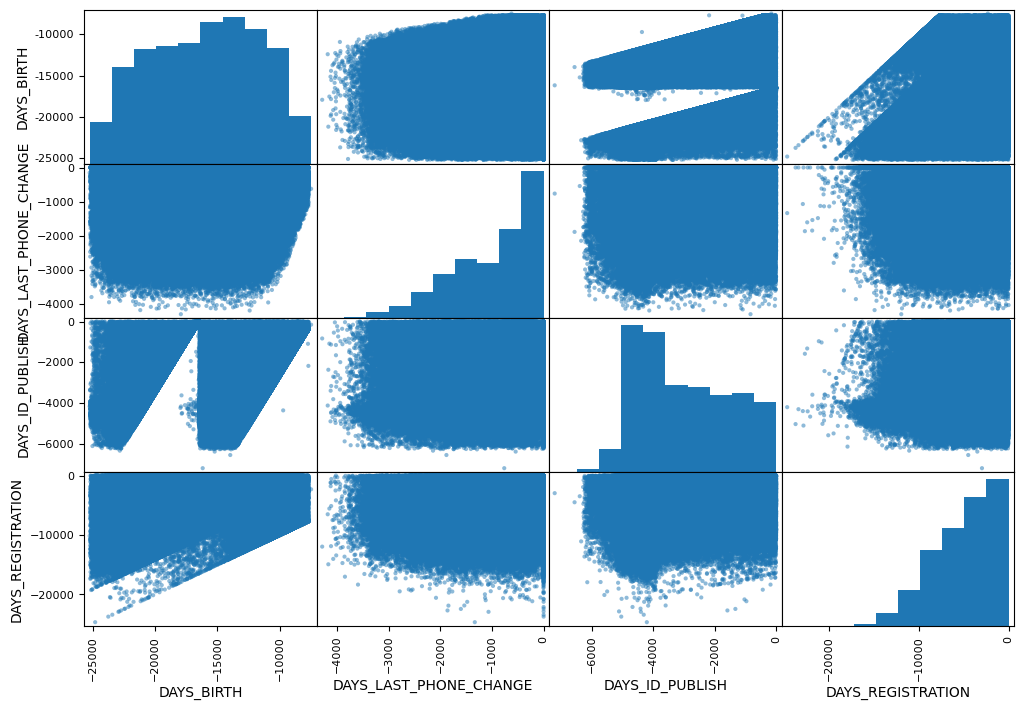

In [12]:
corrM = train.corr(numeric_only=True)
TM = corrM['TARGET'].sort_values(ascending=False)
attributes = TM.iloc[1:11].index 
numeric_like = [c for c in attributes if train[c].nunique() > 60] # crude but effective filter
pd.plotting.scatter_matrix(train[numeric_like[:4]], figsize=(12, 8))

<Axes: xlabel='REGION_RATING_CLIENT', ylabel='DAYS_BIRTH'>

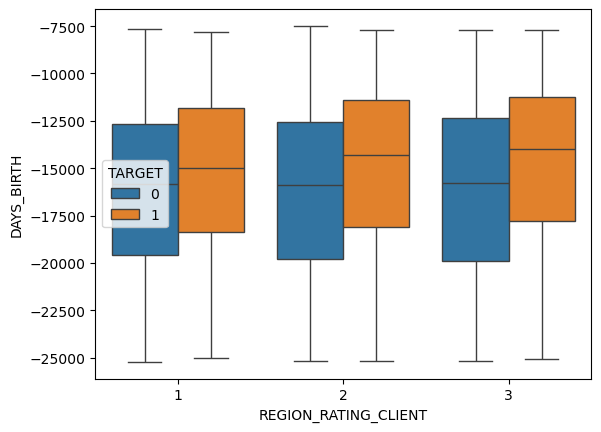

In [14]:
sns.boxplot(x='REGION_RATING_CLIENT', y='DAYS_BIRTH', data=train, hue='TARGET')

# Encoding Categorical data

In [ ]:
"""
We implement the following poilicy:
Categorical data with 2 unique values ------> Label/Ordinal encoding
Categorical data with k>2 unique values ------> OH encoding
"""
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder

OH_encoder = OneHotEncoder()
Ord_encoder = OrdinalEncoder()

cat_var = train.select_dtypes(include='object')
num_var = train.select_dtypes(exclude='object')

OH_list = []
Ord_list = []
for col in cat_var.columns:
    if cat_var[col].nunique() > 2:
        OH_list.append(col)
    else:
        Ord_list.append(col)

OH_data = cat_var.drop(Ord_list, axis=1)
Ord_data = cat_var.drop(OH_list, axis=1)

Ord_trans = pd.DataFrame(Ord_encoder.fit_transform(Ord_data), columns=Ord_data.columns, index=Ord_data.index)

OH_transformed = OH_encoder.fit_transform(OH_data)
OH_trans = pd.DataFrame(
    OH_transformed.toarray(), 
    columns=OH_encoder.get_feature_names_out(), 
    index=OH_data.index
)

cat_var = pd.concat([Ord_trans, OH_trans], axis=1)





,NAME_CONTRACT_TYPE,FLAG_OWN_CAR,FLAG_OWN_REALTY,EMERGENCYSTATE_MODE,CODE_GENDER_F,CODE_GENDER_M,CODE_GENDER_XNA,NAME_TYPE_SUITE_Children,NAME_TYPE_SUITE_Family,NAME_TYPE_SUITE_Group of people,...,HOUSETYPE_MODE_terraced house,HOUSETYPE_MODE_nan,WALLSMATERIAL_MODE_Block,WALLSMATERIAL_MODE_Mixed,WALLSMATERIAL_MODE_Monolithic,WALLSMATERIAL_MODE_Others,WALLSMATERIAL_MODE_Panel,"WALLSMATERIAL_MODE_Stone, brick",WALLSMATERIAL_MODE_Wooden,WALLSMATERIAL_MODE_nan
0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
1,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,1.0,1.0,1.0,NaN,0.0,1.0,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
307508,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
307509,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
307510,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
